# Projekt Digital Finance: Anomalie-Erkennung in Finanzdaten
**Automatisierte Prüfung von Tankkartenbuchungen mit Python**

In diesem Projekt wird mithilfe von Python in einem Jupyter Notebook ein Verfahren zur automatisierten Erkennung auffälliger Tankbuchungen umgesetzt. Grundlage sind simulierte Tankkarten-Buchungen eines fiktiven Gebäudetechnik-Dienstleisters (Musterunternehmen GmbH) mit 80 Firmenfahrzeugen im Jahr 2025.

Ziel der Analyse:
1. Fuhrpark anlegen -> 80 Fahrzeuge in vier Klassen mit Tankvolumen, Verbrauch, Fahrleistung und Kostenstelle
2. Tankbuchungen erzeugen -> realitätsnahe Tankvorgänge eines Jahres (mehrere tausend Buchungen)
3. Anomalien einbauen -> sieben Arten von Auffälligkeiten mit Kennzeichnung (Label)
4. Plausibilitätsprüfung -> Kennzahlen und Verteilungen der Demodaten
5. Anomalie-Erkennung -> regelbasiert, statistisch (IQR / z-Score), Machine Learning (Isolation Forest)
6. Validierung -> Precision, Recall, F1, Erkennungsrate je Anomalietyp, Fehlalarme
7. Management-Visualisierung -> KPI-Übersicht, Auffälligkeitsliste, Heatmap, Kostenstellen
8. Fazit

In [1]:
#Fiktives Unternehmen und Untersuchungszeitraum
UNTERNEHMEN = "Musterunternehmen GmbH (fiktiv)"
JAHR = 2025 #Untersuchungsjahr der Tankbuchungen
SEED = 42 #Fester Startwert -> reproduzierbare Daten

#Kraftstoffpreise: ADAC-Monatsmittel 2025 in EUR je Liter (Januar bis Dezember)
PREISE = {
    "Benzin": [1.737, 1.753, 1.701, 1.692, 1.678, 1.684, 1.674, 1.661, 1.666, 1.672, 1.686, 1.653], #Super E10
    "Diesel": [1.678, 1.687, 1.627, 1.586, 1.558, 1.585, 1.617, 1.580, 1.587, 1.589, 1.642, 1.598],
}
PREIS_STREUUNG = 0.025 #Std.-Abw. je Tankvorgang (Tag, Uhrzeit, Tankstelle) in EUR je Liter
AUFSCHLAG_AUTOBAHN = 0.43 #ADAC-Stichprobe Juli 2025: ca. 42-44 Cent Mehrpreis je Liter
ANTEIL_AUTOBAHN = 0.05 #Anteil der Tankvorgänge an Autobahntankstellen (Annahme)
UST_SATZ = 0.19
SACHKONTO = "4530 Laufende Kfz-Betriebskosten" #SKR03

#Annahmen Anomalien und Erkennung
ANOMALIE_ANTEIL = 0.03 #Anteil eingebauter Auffälligkeiten
Z_GRENZE = 3.0 #Grenzwert für den z-Score (Literpreis)
IQR_FAKTOR = 1.5 #Faktor der IQR-Regel (Verbrauch), Standard der Boxplot-Regel (Chandola et al., 2009, S. 15:30)
KONTAMINATION = 0.03 #Erwarteter Anomalieanteil im Isolation Forest

#Annahmen Prüfaufwand im Controlling
MINUTEN_PRO_BELEG = 3 #Manuelle Sichtprüfung je Buchung
MINUTEN_PRO_FALL = 10 #Gezielte Prüfung je gemeldeter Auffälligkeit
STICHPROBE = 0.10 #Bisherige Stichprobenprüfung (10 % der Belege)

#Bibliotheken
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from matplotlib.colors import LinearSegmentedColormap

#Farben der Grafiken passend zur Präsentation
FARBEN = ["#5A6778", "#2A9D8F", "#A9B6C6"] #Precision, Recall, F1
HEAT_FARBEN = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#CDEBE7", "#2A9D8F", "#1B2A41"])

pd.set_option("display.max_columns",30)
if int(pd.__version__.split(".")[0]) < 3: #ab pandas 3.0 immer aktiv
    pd.options.mode.copy_on_write = True
rng = np.random.default_rng(SEED)

## 1) Fuhrpark anlegen
- Vier Fahrzeugklassen mit Kraftstoff, Tankvolumen, Durchschnittsverbrauch, Fahrleistung und Kostenstelle festlegen
- 80 Fahrzeuge erzeugen, jedes mit festem Fahrer, eigener Verbrauchs- und Fahrleistungsabweichung und zwei Stammtankstellen
- Kontrolle der Anzahl und Kennwerte je Klasse zur Vermeidung späterer Fehler

In [2]:
#Fahrzeugklassen (Annahmen)
KLASSEN = pd.DataFrame([
    #Klasse, Kraftstoff, Tank (l), Verbrauch (l/100 km), Anzahl, km pro Monat, Kostenstelle
    ("Transporter",  "Diesel", 70, 9.0, 40, 3000, "KST-200 Service"),
    ("Mittelklasse", "Diesel", 55, 6.5, 20, 2600, "KST-300 Vertrieb"),
    ("Kleinwagen",   "Benzin", 45, 6.5, 15, 1500, "KST-100 Verwaltung"),
    ("Oberklasse",   "Benzin", 70, 8.5,  5, 2500, "KST-000 Geschäftsführung"),
], columns=["klasse","kraftstoff","tank_l","verbrauch_l100","anzahl","km_monat","kostenstelle"])

#Tankstellen (fiktiv)
TANKSTELLEN = ["TS-01 Düsseldorf-Nord","TS-02 Düsseldorf-Süd","TS-03 Neuss","TS-04 Meerbusch",
               "TS-05 Krefeld","TS-06 Mönchengladbach","TS-07 Ratingen","TS-08 Hilden"]
AUTOBAHN = ["TS-A1 Autobahn A57","TS-A2 Autobahn A3"]

#Fahrzeuge erzeugen
fahrzeuge = []
nr = 1
for _, k in KLASSEN.iterrows():
    for _ in range(int(k["anzahl"])):
        stamm = rng.choice(TANKSTELLEN, size=2, replace=False)
        fahrzeuge.append({
            "fahrzeug_id": f"FZ-{nr:03d}",
            "mitarbeiter_id": f"MA-{nr:03d}", #Ein fester Fahrer je Fahrzeug
            "klasse": k["klasse"],
            "kostenstelle": k["kostenstelle"],
            "kraftstoff_soll": k["kraftstoff"],
            "tank_l": int(k["tank_l"]),
            "verbrauch_l100": round(k["verbrauch_l100"] * rng.normal(1, 0.05), 2), #Fahrzeugindividuell ±5 %
            "km_monat": round(k["km_monat"] * rng.normal(1, 0.15)), #Fahrzeugindividuell ±15 %
            "km_start": int(rng.integers(5_000, 120_000)), #Kilometerstand am 01.01.
            "stamm_1": stamm[0],
            "stamm_2": stamm[1],
        })
        nr += 1
fahrzeuge = pd.DataFrame(fahrzeuge)

#Kontrolle je Klasse
klassen_df = fahrzeuge.groupby("klasse").agg(
    Anzahl=("fahrzeug_id","count"),
    Tank_l=("tank_l","first"),
    Verbrauch_l100=("verbrauch_l100","mean"),
    km_pro_Monat=("km_monat","mean"),
).round(1)
klassen_df

,Anzahl,Tank_l,Verbrauch_l100,km_pro_Monat
klasse,,,,
Kleinwagen,15,45,6.5,1410.5
Mittelklasse,20,55,6.5,2602.2
Oberklasse,5,70,8.8,2215.8
Transporter,40,70,9.0,3008.6


## 2) Tankbuchungen erzeugen
- Je Fahrzeug wird das Jahr Tankvorgang für Tankvorgang simuliert
- Getankt wird, wenn der Tank auf 15–35 % Restmenge gefallen ist (Volltanken)
- Gefahrene Kilometer ergeben sich aus Tankmenge und Verbrauch (±8 % Schwankung je Tankfüllung)
- Das Datum folgt aus der Fahrleistung, getankt wird überwiegend werktags zwischen 6 und 20 Uhr; Sonntage bleiben nur selten bestehen (ca. 2 %, Notdienst), Feiertage NRW 2025 werden verschoben
- Preis = ADAC-Monatsmittel 2025 der Kraftstoffart + zufällige Schwankung je Tankvorgang (±2,5 Cent), an Autobahntankstellen (ca. 5 % der Tankvorgänge) mit 43 Cent Aufschlag
- Kontrolle der letzten Buchungen zur Vermeidung späterer Fehler

In [3]:
#Gesetzliche Feiertage NRW 2025
FEIERTAGE = pd.to_datetime(["2025-01-01","2025-04-18","2025-04-21","2025-05-01","2025-05-29","2025-06-09",
                            "2025-06-19","2025-10-03","2025-11-01","2025-12-25","2025-12-26"])

#Tankvorgänge je Fahrzeug simulieren
#Idee: Jedes Fahrzeug fährt durch das Jahr. Ist der Tank fast leer, wird vollgetankt und eine Buchung entsteht.
buchungen = []
for _, fz in fahrzeuge.iterrows():
    #Startwerte des Fahrzeugs: erster Tag, Kilometerstand und Kilometer je Tag
    datum = pd.Timestamp(f"{JAHR}-01-01") + pd.Timedelta(days=float(rng.uniform(0, 6)))
    km = fz["km_start"]
    km_pro_tag = fz["km_monat"] * 12 / 365

    #Eine Runde der Schleife = eine Tankung
    while True:
        #Menge: Getankt wird bei 15-35 % Restmenge, dann (fast) voll
        rest = rng.uniform(0.15, 0.35) #Restmenge im Tank beim Tanken
        liter = fz["tank_l"] * (1 - rest) * rng.uniform(0.95, 1.0) #Volltanken

        #Strecke: getankte Liter geteilt durch den Verbrauch (±8 % Schwankung)
        gefahren = liter / (fz["verbrauch_l100"] * rng.normal(1, 0.08)) * 100 #km seit letzter Tankung

        #Datum: Strecke geteilt durch km je Tag = Tage bis zur nächsten Tankung
        datum = (datum + pd.Timedelta(days=gefahren / km_pro_tag)).normalize()

        #Wochenende und Feiertage überwiegend auf den nächsten Werktag verschieben
        #(ein kleiner Teil bleibt am Wochenende, z. B. Notdienst)
        while True:
            if datum in FEIERTAGE and rng.random() < 0.95:
                datum = datum + pd.Timedelta(days=1) #Feiertag -> nächster Tag
            elif datum.dayofweek == 5 and rng.random() < 0.70:
                datum = datum + pd.Timedelta(days=2) #Samstag -> Montag
            elif datum.dayofweek == 6 and rng.random() < 0.98:
                datum = datum + pd.Timedelta(days=1) #Sonntag -> Montag
            else:
                break

        #Jahresende erreicht -> weiter mit dem nächsten Fahrzeug
        if datum.year > JAHR:
            break

        #Uhrzeit innerhalb der Arbeitszeit (6 bis 19 Uhr, meist um die Mittagszeit)
        stunde = int(np.clip(rng.normal(12, 3.5), 6, 19))
        zeitpunkt = datum + pd.Timedelta(hours=stunde, minutes=int(rng.integers(0, 60)))
        km = km + gefahren

        #Tankstelle: meist eine der zwei Stammtankstellen, selten Autobahn
        autobahn = rng.random() < ANTEIL_AUTOBAHN
        tankstelle = rng.choice(AUTOBAHN) if autobahn else (fz["stamm_1"] if rng.random() < 0.6 else fz["stamm_2"])

        #Preis: ADAC-Monatsmittel + kleine Streuung, an der Autobahn mit Aufschlag
        monatspreis = PREISE[fz["kraftstoff_soll"]][zeitpunkt.month - 1] #ADAC-Monatsmittel
        preis = monatspreis + rng.normal(0, PREIS_STREUUNG) + (AUFSCHLAG_AUTOBAHN if autobahn else 0)

        #Buchung speichern
        buchungen.append({
            "zeitpunkt": zeitpunkt,
            "fahrzeug_id": fz["fahrzeug_id"],
            "mitarbeiter_id": fz["mitarbeiter_id"],
            "klasse": fz["klasse"],
            "kostenstelle": fz["kostenstelle"],
            "tank_l": fz["tank_l"],
            "kraftstoff_soll": fz["kraftstoff_soll"],
            "kraftstoff_ist": fz["kraftstoff_soll"],
            "tankstelle": tankstelle,
            "liter": round(liter, 2),
            "preis_pro_liter": round(preis, 3),
            "km_stand": int(round(km)),
        })

#Alle Buchungen als Tabelle, sortiert nach Fahrzeug und Zeit
buchungen = pd.DataFrame(buchungen).sort_values(["fahrzeug_id","zeitpunkt"]).reset_index(drop=True)
buchungen["is_anomaly"] = False #Kennzeichnung (Label) für die spätere Validierung
buchungen["anomalie_typ"] = "keine"

if buchungen.empty:
    raise SystemExit("Keine Buchungen erzeugt. Prüfe Fahrzeugklassen und Zeitraum.")
buchungen.tail()

,zeitpunkt,fahrzeug_id,mitarbeiter_id,klasse,kostenstelle,tank_l,kraftstoff_soll,kraftstoff_ist,tankstelle,liter,preis_pro_liter,km_stand,is_anomaly,anomalie_typ
4130,2025-12-01 15:47:00,FZ-080,MA-080,Oberklasse,KST-000 Geschäftsführung,70,Benzin,Benzin,TS-03 Neuss,49.79,1.695,146522,False,keine
4131,2025-12-08 18:55:00,FZ-080,MA-080,Oberklasse,KST-000 Geschäftsführung,70,Benzin,Benzin,TS-02 Düsseldorf-Süd,51.90,1.655,147209,False,keine
4132,2025-12-15 10:43:00,FZ-080,MA-080,Oberklasse,KST-000 Geschäftsführung,70,Benzin,Benzin,TS-02 Düsseldorf-Süd,56.45,1.660,147939,False,keine
4133,2025-12-20 12:44:00,FZ-080,MA-080,Oberklasse,KST-000 Geschäftsführung,70,Benzin,Benzin,TS-03 Neuss,46.65,1.655,148511,False,keine
4134,2025-12-29 15:32:00,FZ-080,MA-080,Oberklasse,KST-000 Geschäftsführung,70,Benzin,Benzin,TS-02 Düsseldorf-Süd,49.01,1.595,149043,False,keine


## 3) Anomalien einbauen
- Insgesamt ca. 3 % der Buchungen werden gezielt verändert und gekennzeichnet (`is_anomaly`, `anomalie_typ`)
- Sieben Anomalietypen mit realem Hintergrund:
  1. Tankmenge über Tankvolumen -> zusätzlicher Kanister oder zweites Fahrzeug betankt
  2. Falscher Kraftstoff -> Privatfahrzeug mit anderer Kraftstoffart betankt
  3. Kilometerstand unplausibel -> rückläufiger km-Stand durch Tippfehler oder Manipulation
  4. Überhöhter Verbrauch -> Tankmenge passt nicht zur gefahrenen Strecke (Abzweigen von Kraftstoff)
  5. Außerhalb der Arbeitszeit -> Tankvorgang nachts oder am Sonntag (private Nutzung)
  6. Preisausreißer -> stark überhöhter Literpreis (Premiumkraftstoff, manipulierter Beleg)
  7. Doppelbuchung -> derselbe Tankvorgang wird ein zweites Mal abgerechnet
- Danach Berechnung von Brutto-, Netto- und Umsatzsteuerbetrag sowie Vergabe der Buchungsnummern
- Speichern des Datensatzes als CSV (Ergebnis Phase 1)

In [4]:
#Vorbereitung: Vorgängerwerte je Fahrzeug (letzte und nächste Tankung desselben Fahrzeugs)
buchungen["km_vorher"] = buchungen.groupby("fahrzeug_id")["km_stand"].shift(1)
buchungen["zeit_vorher"] = buchungen.groupby("fahrzeug_id")["zeitpunkt"].shift(1)
buchungen["zeit_nachher"] = buchungen.groupby("fahrzeug_id")["zeitpunkt"].shift(-1)
nicht_erste = buchungen["km_vorher"].notna() #Erste Tankung hat keinen Vergleichswert
ANZAHL_JE_TYP = int(round(len(buchungen) * ANOMALIE_ANTEIL / 7)) #3 % aller Buchungen, verteilt auf 7 Typen

#Zufällige Auswahl noch unveränderter Buchungen und Kennzeichnung als Anomalie
def ziehen(maske, typ):
    frei = buchungen.index[maske & ~buchungen["is_anomaly"]] #nur Buchungen, die noch keine Anomalie sind
    auswahl = rng.choice(frei, size=ANZAHL_JE_TYP, replace=False)
    buchungen.loc[auswahl, "is_anomaly"] = True
    buchungen.loc[auswahl, "anomalie_typ"] = typ
    return auswahl

#1 Tankmenge über Tankvolumen: 15-60 % mehr Liter, als in den Tank passen (z. B. Kanister)
idx = ziehen(nicht_erste, "Tankmenge über Tankvolumen")
buchungen.loc[idx, "liter"] = (buchungen.loc[idx, "tank_l"] * rng.uniform(1.15, 1.6, len(idx))).round(2)

#2 Falscher Kraftstoff: Diesel statt Benzin bzw. umgekehrt (z. B. Privatfahrzeug)
idx = ziehen(nicht_erste, "Falscher Kraftstoff")
buchungen.loc[idx, "kraftstoff_ist"] = buchungen.loc[idx, "kraftstoff_soll"].map({"Diesel": "Benzin", "Benzin": "Diesel"})
#Preis passend zum getankten Kraftstoff: Monatsmittel + Streuung
streuung = rng.normal(0, PREIS_STREUUNG, len(idx))
for nr, i in enumerate(idx):
    kraftstoff = buchungen.at[i, "kraftstoff_ist"]
    monat = buchungen.at[i, "zeitpunkt"].month
    buchungen.at[i, "preis_pro_liter"] = np.round(PREISE[kraftstoff][monat - 1] + streuung[nr], 3)

#3 Kilometerstand unplausibel: km-Stand kleiner als bei der letzten Tankung (Tippfehler oder Manipulation)
idx = ziehen(nicht_erste, "Kilometerstand unplausibel")
for i in np.sort(idx): #Vorgänger ist dasselbe Fahrzeug (Sortierung nach Fahrzeug und Zeit)
    buchungen.at[i, "km_stand"] = int(buchungen.at[i - 1, "km_stand"] - rng.integers(50, 3000))

#4 Überhöhter Verbrauch: 35-60 % mehr Liter, Tankmenge bleibt aber unter dem Tankvolumen
idx = ziehen(nicht_erste & (buchungen["liter"] < 0.72 * buchungen["tank_l"]), "Überhöhter Verbrauch")
buchungen.loc[idx, "liter"] = np.minimum(buchungen.loc[idx, "liter"] * rng.uniform(1.35, 1.6, len(idx)),
                                         buchungen.loc[idx, "tank_l"] * 0.99).round(2)

#5 Außerhalb der Arbeitszeit: nachts zwischen 22 und 5 Uhr, wenn möglich am Sonntag
idx = ziehen(nicht_erste & buchungen["zeit_nachher"].notna(), "Außerhalb der Arbeitszeit")
for i in idx:
    tag = buchungen.at[i, "zeitpunkt"].normalize()
    sonntag = tag + pd.Timedelta(days=(6 - tag.dayofweek)) #Sonntag derselben Woche
    if buchungen.at[i, "zeit_vorher"] < sonntag < buchungen.at[i, "zeit_nachher"].normalize(): #Reihenfolge der Tankungen bleibt erhalten
        tag = sonntag
    buchungen.at[i, "zeitpunkt"] = tag + pd.Timedelta(hours=int(rng.choice([22, 23, 0, 1, 2, 3, 4])), minutes=int(rng.integers(0, 60)))

#6 Preisausreißer: Literpreis 25-50 % über dem üblichen Preis
idx = ziehen(nicht_erste, "Preisausreißer")
buchungen.loc[idx, "preis_pro_liter"] = (buchungen.loc[idx, "preis_pro_liter"] * rng.uniform(1.25, 1.5, len(idx))).round(3)

#7 Doppelbuchung: Kopie desselben Tankvorgangs 2-45 Minuten später
idx = rng.choice(buchungen.index[nicht_erste & ~buchungen["is_anomaly"]], size=ANZAHL_JE_TYP, replace=False)
doppelt = buchungen.loc[idx].copy()
doppelt["zeitpunkt"] = doppelt["zeitpunkt"] + pd.to_timedelta(rng.integers(2, 45, len(doppelt)), unit="min")
doppelt["is_anomaly"] = True
doppelt["anomalie_typ"] = "Doppelbuchung"
buchungen = pd.concat([buchungen, doppelt], ignore_index=True)

#Beträge, Buchungsnummer und Sachkonto
buchungen["betrag_brutto"] = (buchungen["liter"] * buchungen["preis_pro_liter"]).round(2)
buchungen["betrag_netto"] = (buchungen["betrag_brutto"] / (1 + UST_SATZ)).round(2)
buchungen["ust"] = (buchungen["betrag_brutto"] - buchungen["betrag_netto"]).round(2)
buchungen["sachkonto"] = SACHKONTO
buchungen = buchungen.sort_values("zeitpunkt").reset_index(drop=True)
buchungen.insert(0, "buchungs_id", [f"TB-{i:05d}" for i in range(1, len(buchungen) + 1)])
buchungen = buchungen.drop(columns=["km_vorher","zeit_vorher","zeit_nachher"]) #Hilfsspalten entfernen

#Datensatz speichern (Ergebnis Phase 1)
buchungen.to_csv(f"tankbuchungen_{JAHR}.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

#Kontrolle: Anzahl je Anomalietyp
anomalien_df = buchungen["anomalie_typ"].value_counts().rename_axis("Anomalietyp").reset_index(name="Anzahl")
anomalien_df

,Anomalietyp,Anzahl
0,keine,4027
1,Überhöhter Verbrauch,18
2,Falscher Kraftstoff,18
3,Kilometerstand unplausibel,18
4,Außerhalb der Arbeitszeit,18
5,Tankmenge über Tankvolumen,18
6,Preisausreißer,18
7,Doppelbuchung,18


## 4) Plausibilitätsprüfung
- Ableiten der Merkmale je Buchung: gefahrene km seit letzter Tankung, Tage seit letzter Tankung, Verbrauch (l/100 km), Tankauslastung, Wochentag, Uhrzeit
- Kennzahlen des Datensatzes zur Prüfung der Realitätsnähe (nur unveränderte Buchungen)
- Verteilung des Verbrauchs, Buchungen je Monat und Preisverlauf je Kraftstoff

In [5]:
#Merkmale je Buchung
daten = buchungen.sort_values(["fahrzeug_id","zeitpunkt"]).reset_index(drop=True)
daten["km_diff"] = daten.groupby("fahrzeug_id")["km_stand"].diff() #Gefahrene km seit letzter Tankung
daten["tage_seit"] = daten.groupby("fahrzeug_id")["zeitpunkt"].diff().dt.total_seconds() / 86400
daten["verbrauch_ist"] = np.where(daten["km_diff"] > 0, daten["liter"] / daten["km_diff"] * 100, np.nan) #l/100 km
daten["auslastung"] = daten["liter"] / daten["tank_l"] #Tankmenge im Verhältnis zum Tankvolumen
daten["monat"] = daten["zeitpunkt"].dt.month
daten["stunde"] = daten["zeitpunkt"].dt.hour
daten["sonn_feiertag"] = (daten["zeitpunkt"].dt.dayofweek == 6) | daten["zeitpunkt"].dt.normalize().isin(FEIERTAGE)

#Kennzahlen (unveränderte Buchungen)
normal = daten[~daten["is_anomaly"]]
ueberblick = {
    "Start": str(daten["zeitpunkt"].min().date()),
    "Ende": str(daten["zeitpunkt"].max().date()),
    "Buchungen": int(daten.shape[0]),
    "davon Anomalien": int(daten["is_anomaly"].sum()),
    "Fahrzeuge": int(daten["fahrzeug_id"].nunique()),
    "Summe brutto (EUR)": float(daten["betrag_brutto"].sum().round(2)),
    "Ø Liter": float(normal["liter"].mean().round(2)),
    "Ø Preis Diesel (EUR/l)": float(normal.loc[normal["kraftstoff_ist"] == "Diesel", "preis_pro_liter"].mean().round(3)),
    "Ø Preis Benzin (EUR/l)": float(normal.loc[normal["kraftstoff_ist"] == "Benzin", "preis_pro_liter"].mean().round(3)),
    "Ø Verbrauch (l/100 km)": float(normal["verbrauch_ist"].mean().round(2)),
    "Ø Tage zwischen Tankungen": float(normal["tage_seit"].mean().round(1)),
}
ueberblick_df = pd.DataFrame([ueberblick])
ueberblick_df

,Start,Ende,Buchungen,davon Anomalien,Fahrzeuge,Summe brutto (EUR),Ø Liter,Ø Preis Diesel (EUR/l),Ø Preis Benzin (EUR/l),Ø Verbrauch (l/100 km),Ø Tage zwischen Tankungen
0,2025-01-06,2025-12-31,4153,126,80,318708.99,46.4,1.631,1.71,8.12,6.9


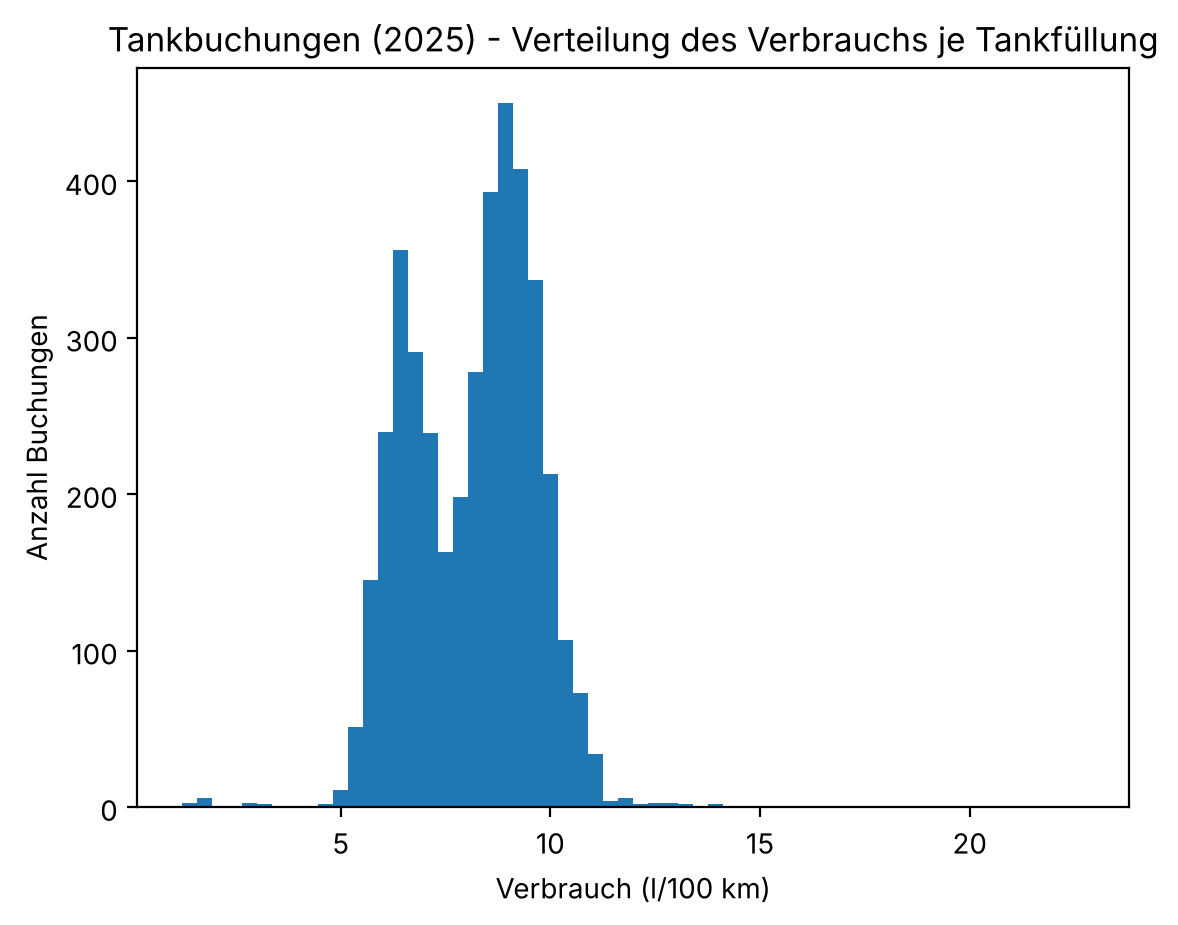

In [6]:
#Verteilung des Verbrauchs je Tankfüllung
daten["verbrauch_ist"].plot(kind="hist", bins=60)
plt.title("Tankbuchungen (2025) - Verteilung des Verbrauchs je Tankfüllung")
plt.xlabel("Verbrauch (l/100 km)")
plt.ylabel("Anzahl Buchungen")
plt.show()

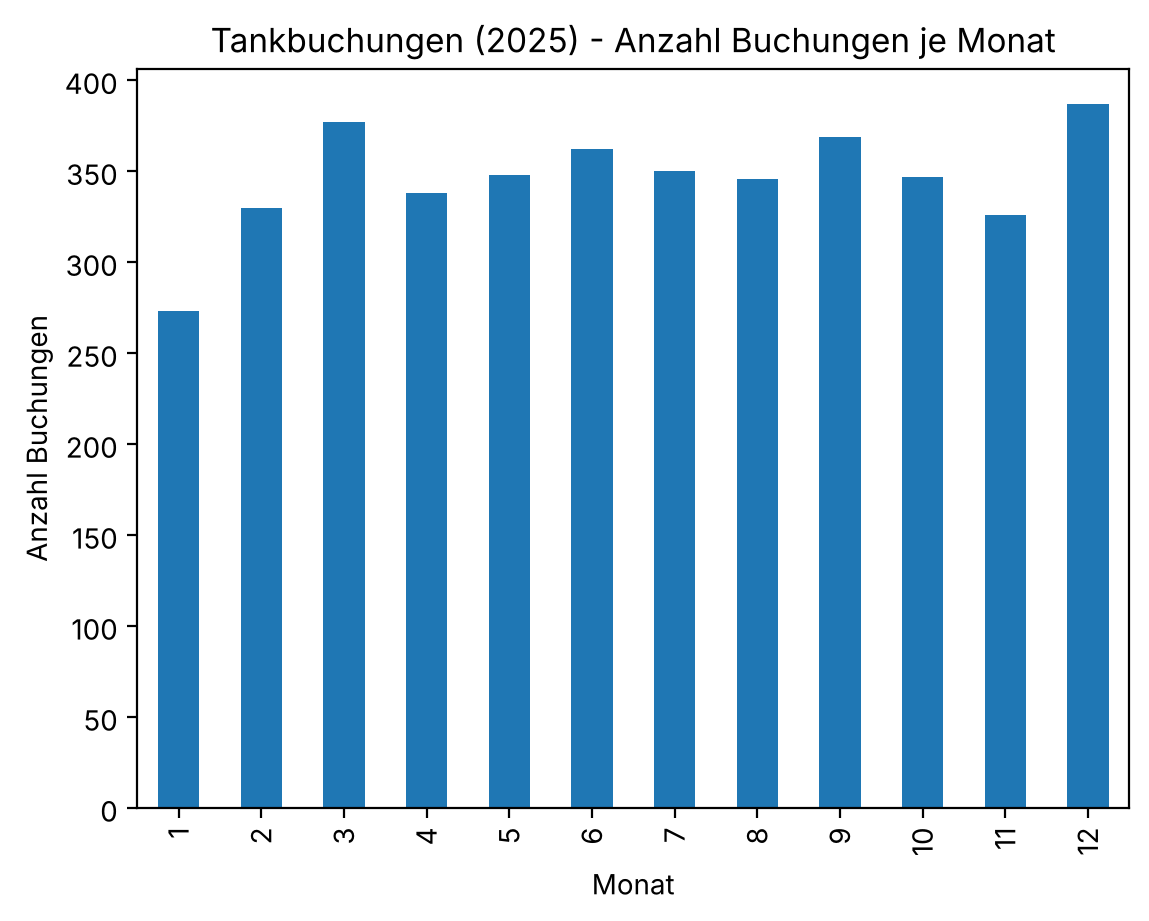

In [7]:
#Buchungen je Monat
daten.groupby("monat")["buchungs_id"].count().plot(kind="bar")
plt.title("Tankbuchungen (2025) - Anzahl Buchungen je Monat")
plt.xlabel("Monat")
plt.ylabel("Anzahl Buchungen")
plt.show()

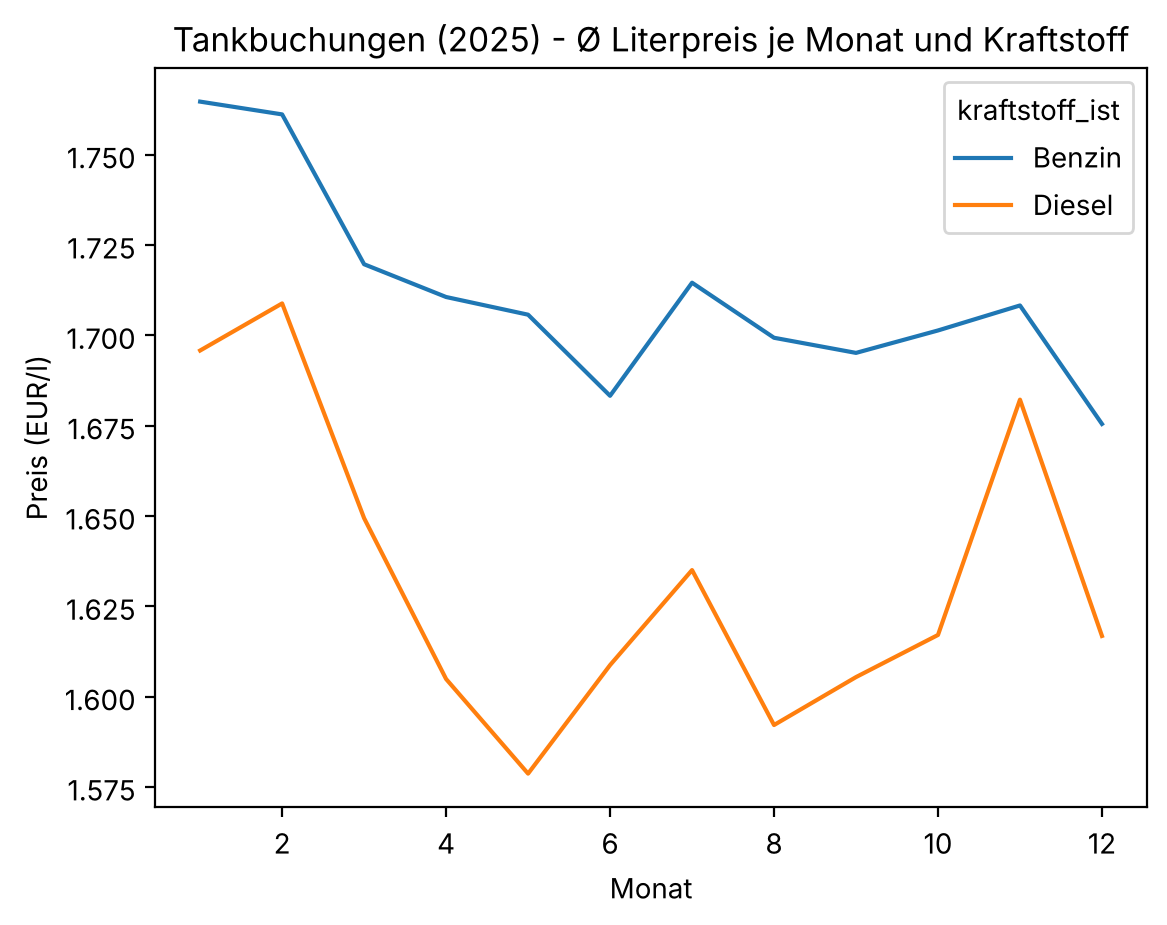

In [8]:
#Preisverlauf je Kraftstoff (Monatsmittel, unveränderte Buchungen)
normal.groupby(["monat","kraftstoff_ist"])["preis_pro_liter"].mean().unstack().plot()
plt.title("Tankbuchungen (2025) - Ø Literpreis je Monat und Kraftstoff")
plt.xlabel("Monat")
plt.ylabel("Preis (EUR/l)")
plt.show()

## 5) Anomalie-Erkennung
- **5.1 Regeln:** feste Plausibilitätsregeln aus Fachwissen (Tankvolumen, Kraftstoffart, km-Stand, Doppelbuchung, Arbeitszeit) -> für das Controlling direkt nachvollziehbar
- **5.2 Statistik (IQR / z-Score):** Verbrauch je Fahrzeug über die Interquartilsabstand-Regel (auffällig oberhalb Q3 + 1,5 · IQR, Chandola et al., 2009, S. 15:30); Literpreis über den z-Score im Vergleich zum Monatsmittel derselben Kraftstoffart und desselben Tankstellentyps (Autobahn/normal), auffällig ab |z| > 3
- **5.3 Machine Learning (Isolation Forest):** unüberwachtes Verfahren, das Buchungen isoliert, die sich in mehreren Merkmalen gleichzeitig von der Masse unterscheiden (Liu et al., 2008)
- **5.4 Kombination:** eine Buchung gilt als auffällig, wenn mindestens eine Methode sie meldet

In [9]:
#5.1 Regeln
doppelt = ((daten["liter"] == daten.groupby("fahrzeug_id")["liter"].shift(1))
           & (daten["betrag_brutto"] == daten.groupby("fahrzeug_id")["betrag_brutto"].shift(1))
           & (daten["tage_seit"] * 24 * 60 <= 60)) #Gleicher Betrag innerhalb von 60 Minuten

regeln = {
    "Tankmenge > Tankvolumen": daten["liter"] > daten["tank_l"],
    "Falscher Kraftstoff": daten["kraftstoff_ist"] != daten["kraftstoff_soll"],
    "km-Stand nicht plausibel": daten["km_diff"] <= 0,
    "Mögliche Doppelbuchung": doppelt,
    "Außerhalb Arbeitszeit": (daten["stunde"] < 5) | (daten["stunde"] >= 22) | daten["sonn_feiertag"],
}
regeln_df = pd.DataFrame(regeln)
daten["regel_flag"] = regeln_df.any(axis=1)
daten["regel_grund"] = regeln_df.apply(lambda z: ", ".join(regeln_df.columns[z.values]), axis=1)

#Treffer je Regel
pd.DataFrame({"Regel": regeln_df.columns, "Gemeldet": regeln_df.sum().values})

,Regel,Gemeldet
0,Tankmenge > Tankvolumen,18
1,Falscher Kraftstoff,18
2,km-Stand nicht plausibel,36
3,Mögliche Doppelbuchung,18
4,Außerhalb Arbeitszeit,38


In [10]:
#5.2 Statistik (IQR / z-Score)
#Verbrauch: IQR-Regel je Fahrzeug, nur nach oben (Chandola et al., 2009, S. 15:30)
q1 = daten.groupby("fahrzeug_id")["verbrauch_ist"].transform(lambda x: x.quantile(0.25))
q3 = daten.groupby("fahrzeug_id")["verbrauch_ist"].transform(lambda x: x.quantile(0.75))
daten["grenze_verbrauch"] = q3 + IQR_FAKTOR * (q3 - q1)
verbrauch_hoch = daten["verbrauch_ist"] > daten["grenze_verbrauch"]

#Literpreis: z-Score je Kraftstoff, Monat und Tankstellentyp
daten["autobahn"] = daten["tankstelle"].isin(AUTOBAHN)
gruppe_preis = daten.groupby(["kraftstoff_ist","monat","autobahn"])["preis_pro_liter"]
daten["z_preis"] = (daten["preis_pro_liter"] - gruppe_preis.transform("mean")) / gruppe_preis.transform(lambda x: x.std(ddof=1))
preis_auffaellig = daten["z_preis"].abs() > Z_GRENZE

daten["stat_flag"] = verbrauch_hoch | preis_auffaellig
daten["stat_grund"] = np.where(verbrauch_hoch, "Verbrauch " + daten["verbrauch_ist"].round(1).astype(str) + " l/100 km", "")
daten["stat_grund"] = daten["stat_grund"] + np.where(preis_auffaellig, " Preis z=" + daten["z_preis"].round(1).astype(str), "")

#Kontrolle
daten.loc[daten["stat_flag"], ["buchungs_id","fahrzeug_id","verbrauch_ist","grenze_verbrauch","preis_pro_liter","z_preis","stat_grund"]].tail()

,buchungs_id,fahrzeug_id,verbrauch_ist,grenze_verbrauch,preis_pro_liter,z_preis,stat_grund
3687,TB-04054,FZ-068,7.390476,7.271573,1.628,-1.148765,Verbrauch 7.4 l/100 km
3714,TB-02702,FZ-069,6.778555,8.053447,1.589,-3.112057,Preis z=-3.1
3930,TB-00589,FZ-076,10.850340,10.698776,1.769,0.623595,Verbrauch 10.9 l/100 km
4046,TB-03673,FZ-078,10.742981,11.404948,2.299,6.980965,Preis z=7.0
4062,TB-01071,FZ-079,12.860632,10.109661,1.711,0.955102,Verbrauch 12.9 l/100 km


In [11]:
#5.3 Isolation Forest (Liu et al., 2008; Umsetzung mit scikit-learn, Pedregosa et al., 2011)
median_verbrauch = daten.groupby("fahrzeug_id")["verbrauch_ist"].transform("median")
median_km = daten.groupby("fahrzeug_id")["km_diff"].transform("median")
median_tage = daten.groupby("fahrzeug_id")["tage_seit"].transform("median")
median_preis = daten.groupby(["kraftstoff_ist","monat","autobahn"])["preis_pro_liter"].transform("median")

#Merkmale relativ zum jeweiligen Fahrzeug bzw. Monat (1 = normal)
merkmale = pd.DataFrame({
    "auslastung": daten["auslastung"],
    "verbrauch_rel": (daten["verbrauch_ist"] / median_verbrauch).fillna(1),
    "km_rel": (daten["km_diff"] / median_km).fillna(1),
    "tage_rel": (daten["tage_seit"] / median_tage).fillna(1),
    "preis_rel": daten["preis_pro_liter"] / median_preis,
    "stunde": daten["stunde"],
    "sonn_feiertag": daten["sonn_feiertag"].astype(int),
    "kraftstoff_falsch": (daten["kraftstoff_ist"] != daten["kraftstoff_soll"]).astype(int),
})

modell = IsolationForest(n_estimators=300, contamination=KONTAMINATION, random_state=SEED)
modell.fit(merkmale)
daten["if_score"] = -modell.score_samples(merkmale) #Höher = auffälliger
daten["if_flag"] = modell.predict(merkmale) == -1

#5.4 Kombination
daten["kombi_flag"] = daten["regel_flag"] | daten["stat_flag"] | daten["if_flag"]
daten["anzahl_methoden"] = daten[["regel_flag","stat_flag","if_flag"]].sum(axis=1)

#Kontrolle
daten[["regel_flag","stat_flag","if_flag","kombi_flag"]].sum().rename("Gemeldete Buchungen").to_frame()

,Gemeldete Buchungen
regel_flag,110
stat_flag,85
if_flag,125
kombi_flag,199


## 6) Validierung
- Da die Anomalien selbst eingebaut wurden, ist für jede Buchung bekannt, ob sie tatsächlich auffällig ist (Label)
- Precision -> Anteil der gemeldeten Buchungen, die wirklich auffällig sind (Trefferquote)
- Recall -> Anteil der tatsächlichen Anomalien, die gefunden wurden (Erkennungsrate)
- F1 -> harmonisches Mittel aus Precision und Recall
- Erkennungsrate je Anomalietyp und Analyse der Fehlalarme (False Positives)

In [12]:
#Kennzahlen je Methode
METHODEN = {"Regeln": "regel_flag", "Statistik": "stat_flag",
            "Isolation Forest": "if_flag", "Kombination": "kombi_flag"}

ergebnisse = []
for name, spalte in METHODEN.items():
    tn, fp, fn, tp = confusion_matrix(daten["is_anomaly"], daten[spalte]).ravel()
    ergebnisse.append({
        "Methode": name,
        "Gemeldet": int(tp + fp),
        "Treffer (TP)": int(tp),
        "Fehlalarme (FP)": int(fp),
        "Übersehen (FN)": int(fn),
        "Korrekt normal (TN)": int(tn),
        "Precision": round(float(precision_score(daten["is_anomaly"], daten[spalte])), 3),
        "Recall": round(float(recall_score(daten["is_anomaly"], daten[spalte])), 3),
        "F1": round(float(f1_score(daten["is_anomaly"], daten[spalte])), 3),
    })
kennzahlen_df = pd.DataFrame(ergebnisse)
kennzahlen_df

,Methode,Gemeldet,Treffer (TP),Fehlalarme (FP),Übersehen (FN),Korrekt normal (TN),Precision,Recall,F1
0,Regeln,110,90,20,36,4007,0.818,0.714,0.763
1,Statistik,85,54,31,72,3996,0.635,0.429,0.512
2,Isolation Forest,125,83,42,43,3985,0.664,0.659,0.661
3,Kombination,199,126,73,0,3954,0.633,1.000,0.775


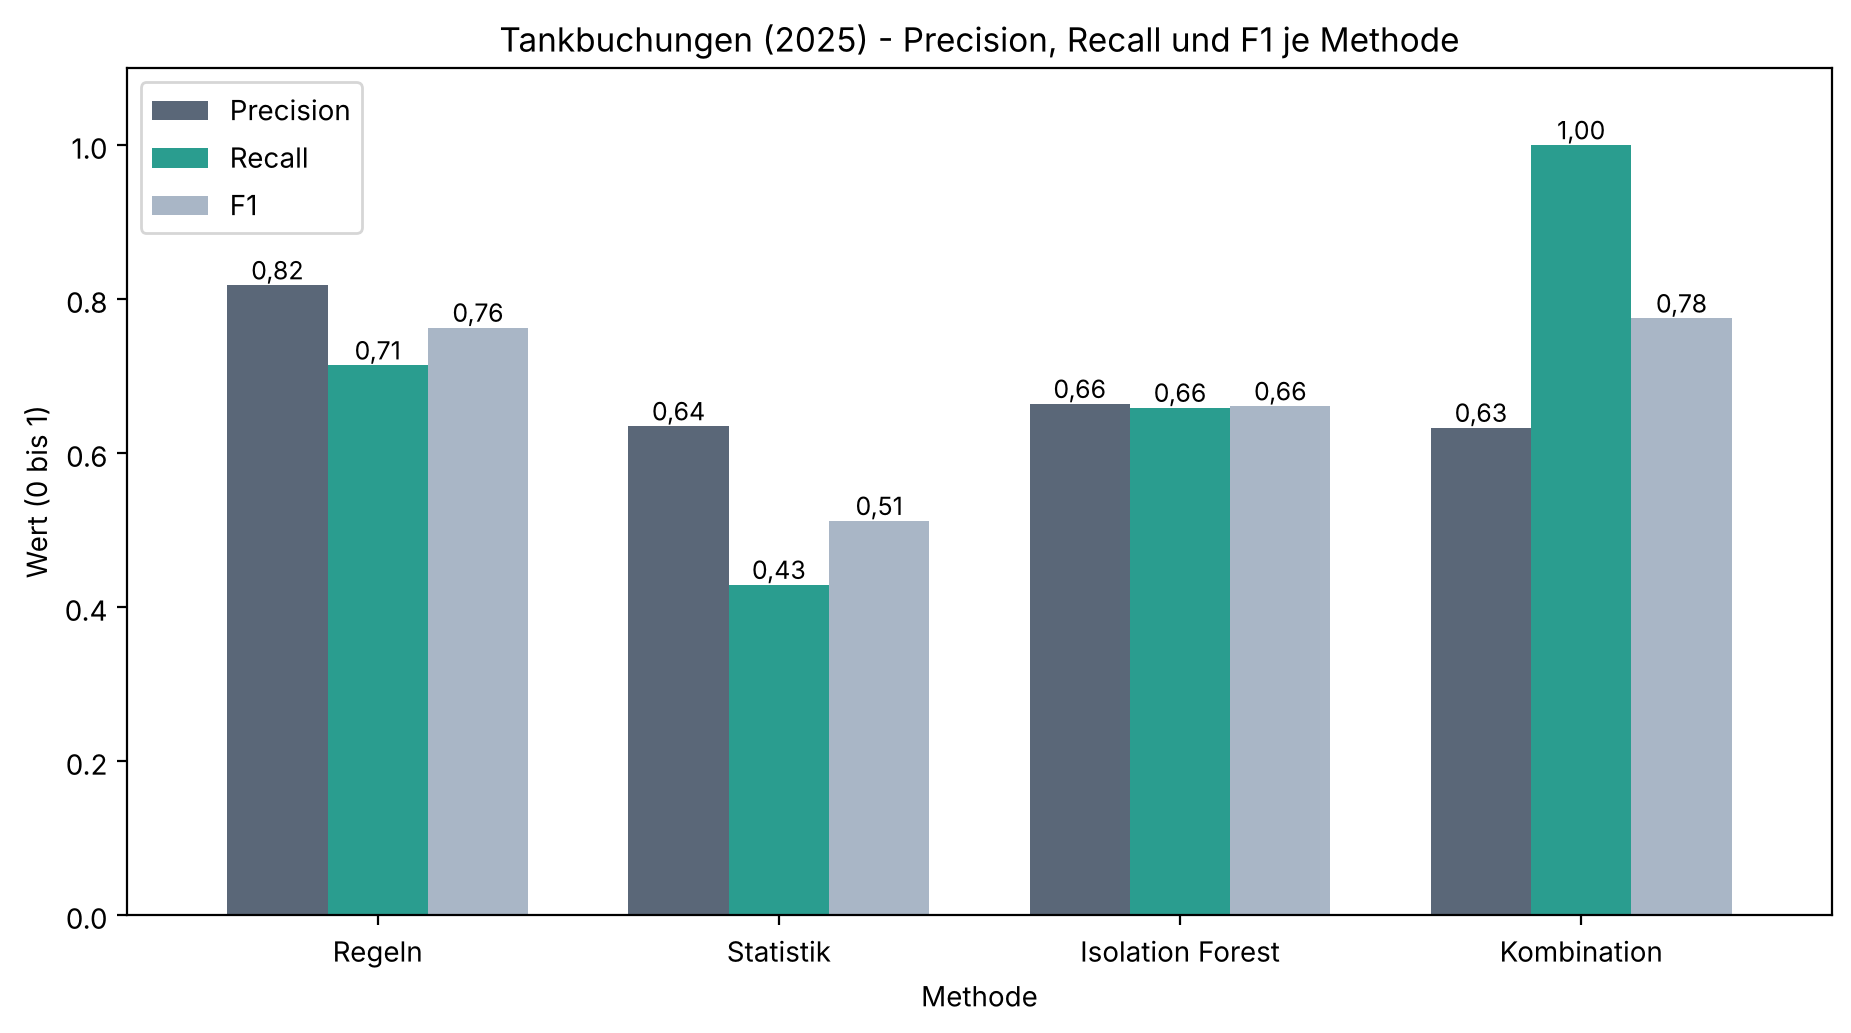

In [13]:
#Precision, Recall und F1 je Methode (Abb. 5 der Präsentation)
ax = kennzahlen_df.set_index("Methode")[["Precision","Recall","F1"]].plot(kind="bar", color=FARBEN, figsize=(11, 5.5), width=0.75)
for balken in ax.containers:
    ax.bar_label(balken, labels=[f"{v:.2f}".replace(".", ",") for v in balken.datavalues], fontsize=9)
plt.title("Tankbuchungen (2025) - Precision, Recall und F1 je Methode")
plt.xlabel("Methode")
plt.ylabel("Wert (0 bis 1)")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.savefig("abb5_precision_recall_f1.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
#Erkennungsrate (Recall) je Anomalietyp
erkennung_df = (daten[daten["is_anomaly"]].groupby("anomalie_typ")[list(METHODEN.values())].mean() * 100).round(1)
erkennung_df.columns = list(METHODEN.keys())
erkennung_df.index.name = "Anomalietyp (Erkennungsrate in %)"
erkennung_df

,Regeln,Statistik,Isolation Forest,Kombination
Anomalietyp (Erkennungsrate in %),,,,
Außerhalb der Arbeitszeit,100.0,0.0,88.9,100.0
Doppelbuchung,100.0,0.0,100.0,100.0
Falscher Kraftstoff,100.0,5.6,33.3,100.0
Kilometerstand unplausibel,100.0,0.0,27.8,100.0
Preisausreißer,0.0,100.0,72.2,100.0
Tankmenge über Tankvolumen,100.0,100.0,100.0,100.0
Überhöhter Verbrauch,0.0,94.4,38.9,100.0


In [15]:
#Analyse der Fehlalarme (Kombination)
fehlalarme = daten[daten["kombi_flag"] & ~daten["is_anomaly"]]
fehlalarme_df = pd.DataFrame({
    "Gemeldet durch Regel": [int(fehlalarme["regel_flag"].sum())],
    "davon Sonntag/Feiertag (Notdienst)": [int((fehlalarme["regel_flag"] & fehlalarme["sonn_feiertag"]).sum())],
    "Gemeldet durch Statistik": [int(fehlalarme["stat_flag"].sum())],
    "Gemeldet durch Isolation Forest": [int(fehlalarme["if_flag"].sum())],
    "davon Autobahntankstelle": [int(fehlalarme["tankstelle"].isin(AUTOBAHN).sum())],
    "Fehlalarme gesamt": [int(len(fehlalarme))],
})
fehlalarme_df

,Gemeldet durch Regel,davon Sonntag/Feiertag (Notdienst),Gemeldet durch Statistik,Gemeldet durch Isolation Forest,davon Autobahntankstelle,Fehlalarme gesamt
0,20,20,31,42,5,73


## 6.1) Vergleich und Sensitivität
- Vergleich des Isolation Forest mit One-Class-SVM und zwei Clusteringverfahren (k-Means, DBSCAN) auf denselben Merkmalen
- Jedes Verfahren allein und in Kombination mit Regeln und Statistik
- Je Verfahren mehrere Parameterwerte, um die Abhängigkeit vom Parameter zu zeigen (kein Herauspicken des besten Werts)
- Isolation Forest mit unterschiedlicher contamination (Sensitivität)
- Die Labels dienen nur der Bewertung, nicht dem Training

In [16]:
#6.1 Vergleich mit One-Class-SVM und Clustering (gleiche Merkmale wie beim Isolation Forest)
#One-Class-SVM, k-Means und DBSCAN arbeiten mit Abständen. Damit kein Merkmal nur wegen seiner Einheit
#(z. B. Stunde 0-23 gegenüber Verhältnis um 1) mehr Gewicht bekommt, werden alle Merkmale standardisiert.
merkmale_std = StandardScaler().fit_transform(merkmale) #Mittelwert 0, Standardabweichung 1
regel_stat = (daten["regel_flag"] | daten["stat_flag"]).to_numpy() #Meldungen von Regeln und Statistik

#Meldungen je Verfahren und Parameter sammeln
varianten = []

#One-Class-SVM: lernt eine Grenze um die normalen Buchungen, alles außerhalb gilt als auffällig
for gamma in [0.05, "scale", 0.2]:
    ocsvm = OneClassSVM(kernel="rbf", nu=KONTAMINATION, gamma=gamma).fit(merkmale_std)
    varianten.append(["One-Class-SVM", f"gamma = {gamma}", ocsvm.predict(merkmale_std) == -1])

#k-Means: bildet k Gruppen; auffällig sind die 3 % Buchungen mit dem größten Abstand zum nächsten Gruppenzentrum
for k in [4, 8]:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(merkmale_std)
    abstand = np.linalg.norm(merkmale_std - kmeans.cluster_centers_[kmeans.labels_], axis=1) #Abstand zum eigenen Zentrum
    grenze = np.quantile(abstand, 1 - KONTAMINATION)
    varianten.append(["k-Means", f"k = {k}", abstand >= grenze])

#DBSCAN: bildet Gruppen aus dicht liegenden Buchungen; Buchungen ohne Gruppe (Rauschen, Label -1) gelten als auffällig
for eps in [1.5, 2.0, 2.5]:
    dbscan = DBSCAN(eps=eps, min_samples=10).fit(merkmale_std)
    varianten.append(["DBSCAN", f"eps = {eps}", dbscan.labels_ == -1])

#Isolation Forest mit verschiedenen erwarteten Anteilen auffälliger Buchungen
for anteil in [0.02, 0.03, 0.05]:
    iforest = IsolationForest(n_estimators=300, contamination=anteil, random_state=SEED).fit(merkmale)
    varianten.append(["Isolation Forest", f"contamination = {anteil}", iforest.predict(merkmale) == -1])

#Zum Vergleich: nur Regeln und Statistik, ohne Machine Learning
varianten.append(["Ohne ML: Regeln + Statistik", "-", regel_stat])

#Kennzahlen je Variante: allein und in Kombination mit Regeln und Statistik
vergleich = []
for verfahren, parameter, meldung in varianten:
    kombi = regel_stat | meldung #auffällig, wenn Regeln/Statistik oder das Verfahren melden
    vergleich.append({
        "Verfahren": verfahren,
        "Parameter": parameter,
        "Gemeldet": int(meldung.sum()),
        "F1 allein": round(float(f1_score(daten["is_anomaly"], meldung)), 3),
        "Recall Kombination": round(float(recall_score(daten["is_anomaly"], kombi)), 3),
        "F1 Kombination": round(float(f1_score(daten["is_anomaly"], kombi)), 3),
    })
vergleich_df = pd.DataFrame(vergleich)
vergleich_df

,Verfahren,Parameter,Gemeldet,F1 allein,Recall Kombination,F1 Kombination
0,One-Class-SVM,gamma = 0.05,122,0.710,1.000,0.764
1,One-Class-SVM,gamma = scale,128,0.638,1.000,0.737
2,One-Class-SVM,gamma = 0.2,125,0.598,1.000,0.735
3,k-Means,k = 4,125,0.805,1.000,0.771
4,k-Means,k = 8,125,0.693,1.000,0.741
5,DBSCAN,eps = 1.5,139,0.800,1.000,0.759
6,DBSCAN,eps = 2.0,108,0.778,1.000,0.787
7,DBSCAN,eps = 2.5,89,0.679,1.000,0.790
8,Isolation Forest,contamination = 0.02,84,0.562,1.000,0.790
9,Isolation Forest,contamination = 0.03,125,0.661,1.000,0.775


## 7) Management-Visualisierung
- KPI-Übersicht für die kaufmännische Leitung: geprüftes Volumen, gemeldete Fälle, Treffer- und Erkennungsquote, betroffenes Buchungsvolumen, Prüfaufwand im Vergleich zur bisherigen Stichprobe
- Auffälligkeitsliste als Arbeitsliste für das Controlling: alle gemeldeten Buchungen, sortiert nach Dringlichkeit (Anzahl Methoden, dann Score); angezeigt werden die 20 dringendsten, die vollständige Liste wird als CSV gespeichert
- Heatmap Fahrzeug × Monat (12 auffälligste Fahrzeuge): zeigt Häufungen auffälliger Buchungen ohne Statistikwissen
- Auffälliges Buchungsvolumen je Kostenstelle
- Speichern der Ergebnisse als CSV (Ergebnisdaten, Kennzahlen, Auffälligkeitsliste, KPI-Übersicht); die Grafiken für die Präsentation werden als PNG gespeichert (Abb. 5 und 7)

In [17]:
#KPI-Übersicht
treffer = daten[daten["kombi_flag"] & daten["is_anomaly"]]
gemeldet = int(daten["kombi_flag"].sum())
kpi = {
    "Geprüfte Buchungen": int(daten.shape[0]),
    "Geprüftes Volumen (EUR)": float(daten["betrag_brutto"].sum().round(2)),
    "Gemeldete Auffälligkeiten": gemeldet,
    "Anteil zu prüfen (%)": round(gemeldet / daten.shape[0] * 100, 1),
    "Trefferquote (%)": round(len(treffer) / gemeldet * 100, 1) if gemeldet != 0 else float("nan"),
    "Erkannte Anomalien (%)": round(len(treffer) / daten["is_anomaly"].sum() * 100, 1),
    "Betroffenes Volumen (EUR)": float(treffer["betrag_brutto"].sum().round(2)),
    "Prüfaufwand Vollprüfung (h)": round(daten.shape[0] * MINUTEN_PRO_BELEG / 60, 1),
    "Prüfaufwand gezielt (h)": round(gemeldet * MINUTEN_PRO_FALL / 60, 1),
    "Erwartete Funde 10 %-Stichprobe": round(float(daten["is_anomaly"].sum() * STICHPROBE), 0),
    "Funde mit Verfahren": int(len(treffer)),
}
kpi_df = pd.DataFrame([kpi])
kpi_df

,Geprüfte Buchungen,Geprüftes Volumen (EUR),Gemeldete Auffälligkeiten,Anteil zu prüfen (%),Trefferquote (%),Erkannte Anomalien (%),Betroffenes Volumen (EUR),Prüfaufwand Vollprüfung (h),Prüfaufwand gezielt (h),Erwartete Funde 10 %-Stichprobe,Funde mit Verfahren
0,4153,318708.99,199,4.8,63.3,100.0,11745.24,207.7,33.2,13.0,126


In [18]:
#Auffälligkeitsliste für das Controlling: alle Meldungen, sortiert nach Dringlichkeit
daten["begruendung"] = (daten["regel_grund"] + " " + daten["stat_grund"]).str.strip()
daten.loc[daten["begruendung"] == "", "begruendung"] = "Muster ungewöhnlich (Isolation Forest)"

liste_df = (daten[daten["kombi_flag"]]
            .sort_values(["anzahl_methoden","if_score"], ascending=False)
            [["buchungs_id","zeitpunkt","fahrzeug_id","mitarbeiter_id","kostenstelle","liter",
              "preis_pro_liter","betrag_brutto","anzahl_methoden","if_score","begruendung"]])
liste_df.columns = ["Buchung","Zeitpunkt","Fahrzeug","Mitarbeiter","Kostenstelle","Liter","EUR/l",
                    "Betrag (EUR)","Methoden","Score","Begründung"]
liste_df["Score"] = liste_df["Score"].round(3)

#Anzeige der 20 dringendsten Fälle (vollständige Liste mit allen Meldungen als CSV)
print("Meldungen in der Arbeitsliste:", len(liste_df))
liste_df.head(20)

Meldungen in der Arbeitsliste: 199


,Buchung,Zeitpunkt,Fahrzeug,Mitarbeiter,Kostenstelle,Liter,EUR/l,Betrag (EUR),Methoden,Score,Begründung
2922,TB-03341,2025-10-22 08:16:00,FZ-050,MA-050,KST-300 Vertrieb,73.45,1.636,120.16,3,0.641,Tankmenge > Tankvolumen Verbrauch 15.2 l/100 km
1030,TB-01032,2025-04-07 10:07:00,FZ-017,MA-017,KST-200 Service,103.41,1.593,164.73,3,0.626,Tankmenge > Tankvolumen Verbrauch 22.7 l/100 km
2089,TB-01210,2025-04-22 11:37:00,FZ-035,MA-035,KST-200 Service,111.28,1.590,176.94,3,0.626,Tankmenge > Tankvolumen Verbrauch 21.0 l/100 km
2366,TB-00240,2025-01-27 15:42:00,FZ-040,MA-040,KST-200 Service,87.41,1.688,147.55,3,0.621,Tankmenge > Tankvolumen Verbrauch 20.4 l/100 km
611,TB-02007,2025-06-30 11:56:00,FZ-010,MA-010,KST-200 Service,111.31,1.562,173.87,3,0.621,Tankmenge > Tankvolumen Verbrauch 17.9 l/100 km
3322,TB-03170,2025-10-07 09:26:00,FZ-058,MA-058,KST-300 Vertrieb,75.71,1.635,123.79,3,0.618,Tankmenge > Tankvolumen Verbrauch 12.9 l/100 km
3112,TB-03429,2025-10-30 12:48:00,FZ-054,MA-054,KST-300 Vertrieb,84.98,1.994,169.45,3,0.613,Tankmenge > Tankvolumen Verbrauch 13.9 l/100 km
3059,TB-02096,2025-07-07 15:00:00,FZ-053,MA-053,KST-300 Vertrieb,70.38,1.629,114.65,3,0.611,Tankmenge > Tankvolumen Verbrauch 11.7 l/100 km
2982,TB-04111,2025-12-29 11:44:00,FZ-051,MA-051,KST-300 Vertrieb,77.37,1.575,121.86,3,0.610,Tankmenge > Tankvolumen Verbrauch 14.0 l/100 km
1311,TB-03990,2025-12-17 13:36:00,FZ-021,MA-021,KST-200 Service,99.35,1.608,159.75,3,0.608,Tankmenge > Tankvolumen Verbrauch 18.7 l/100 km


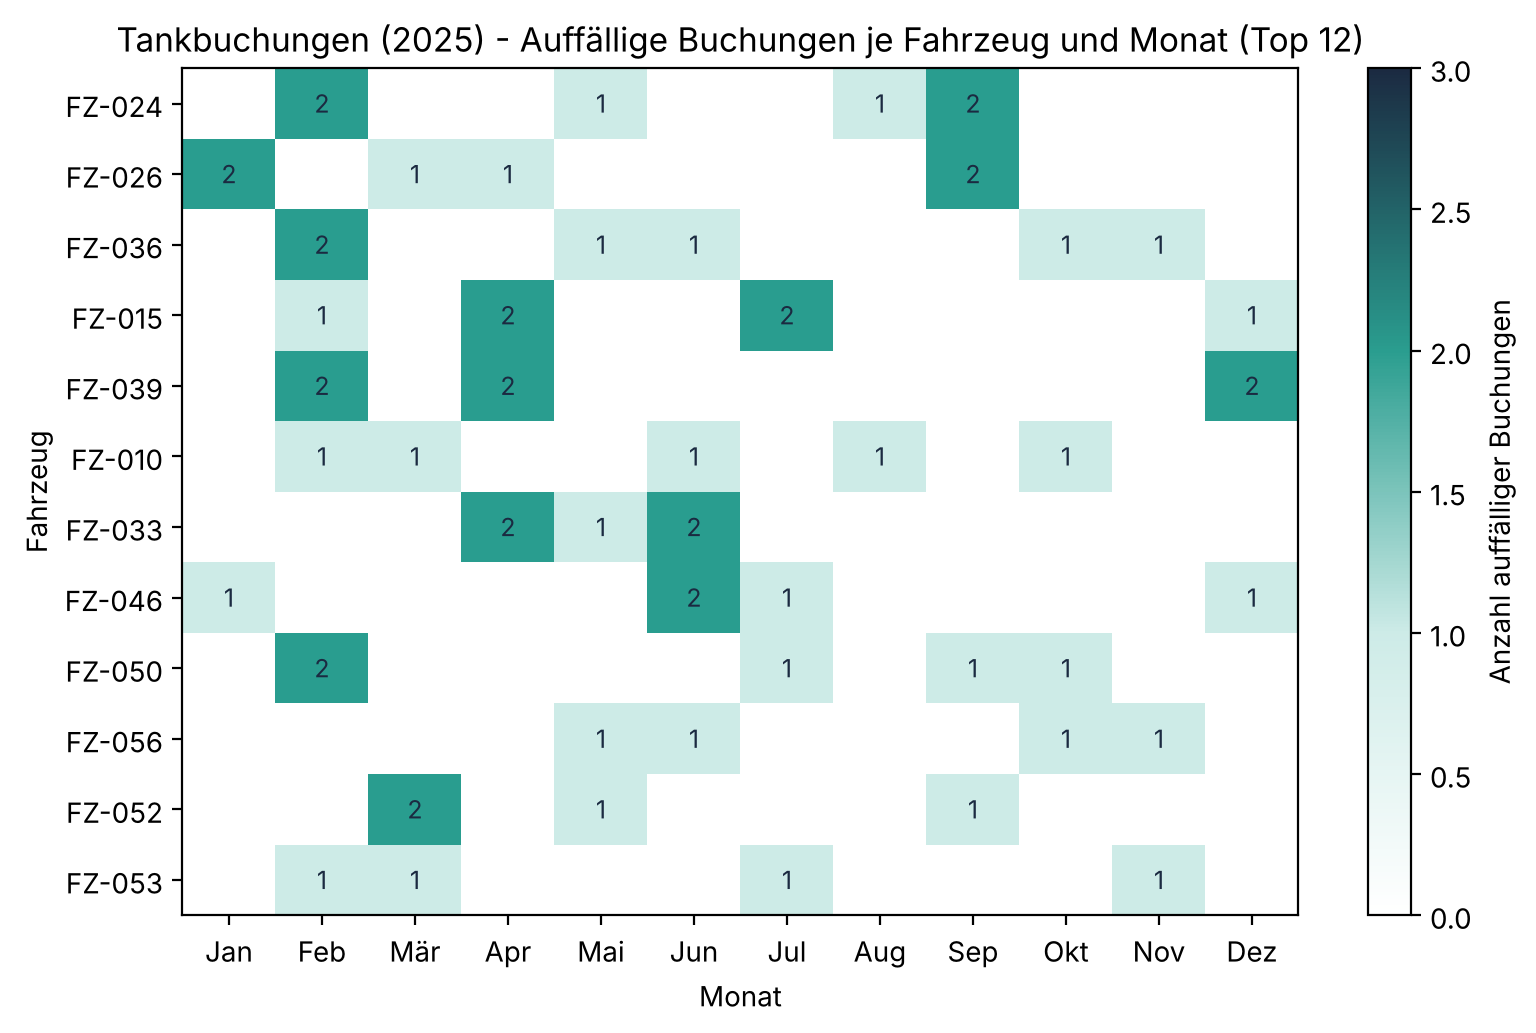

In [19]:
#Heatmap: auffällige Buchungen je Fahrzeug und Monat (12 auffälligste Fahrzeuge, Abb. 7 der Präsentation)
matrix = daten[daten["kombi_flag"]].pivot_table(index="fahrzeug_id", columns="monat", values="buchungs_id",
                                                aggfunc="count", fill_value=0).reindex(columns=range(1, 13), fill_value=0)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index[:12]]

plt.figure(figsize=(9, 5.5))
plt.imshow(matrix, cmap=HEAT_FARBEN, aspect="auto", vmin=0, vmax=max(3, matrix.values.max()))
for i in range(matrix.shape[0]): #Anzahl in jede Zelle schreiben
    for j in range(12):
        if matrix.values[i, j] > 0:
            plt.text(j, i, matrix.values[i, j], ha="center", va="center", fontsize=9, color="white" if matrix.values[i, j] >= 3 else "#1B2A41")
plt.colorbar(label="Anzahl auffälliger Buchungen")
plt.xticks(range(12), ["Jan","Feb","Mär","Apr","Mai","Jun","Jul","Aug","Sep","Okt","Nov","Dez"])
plt.yticks(range(len(matrix)), matrix.index)
plt.title("Tankbuchungen (2025) - Auffällige Buchungen je Fahrzeug und Monat (Top 12)")
plt.xlabel("Monat")
plt.ylabel("Fahrzeug")
plt.savefig("abb7_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

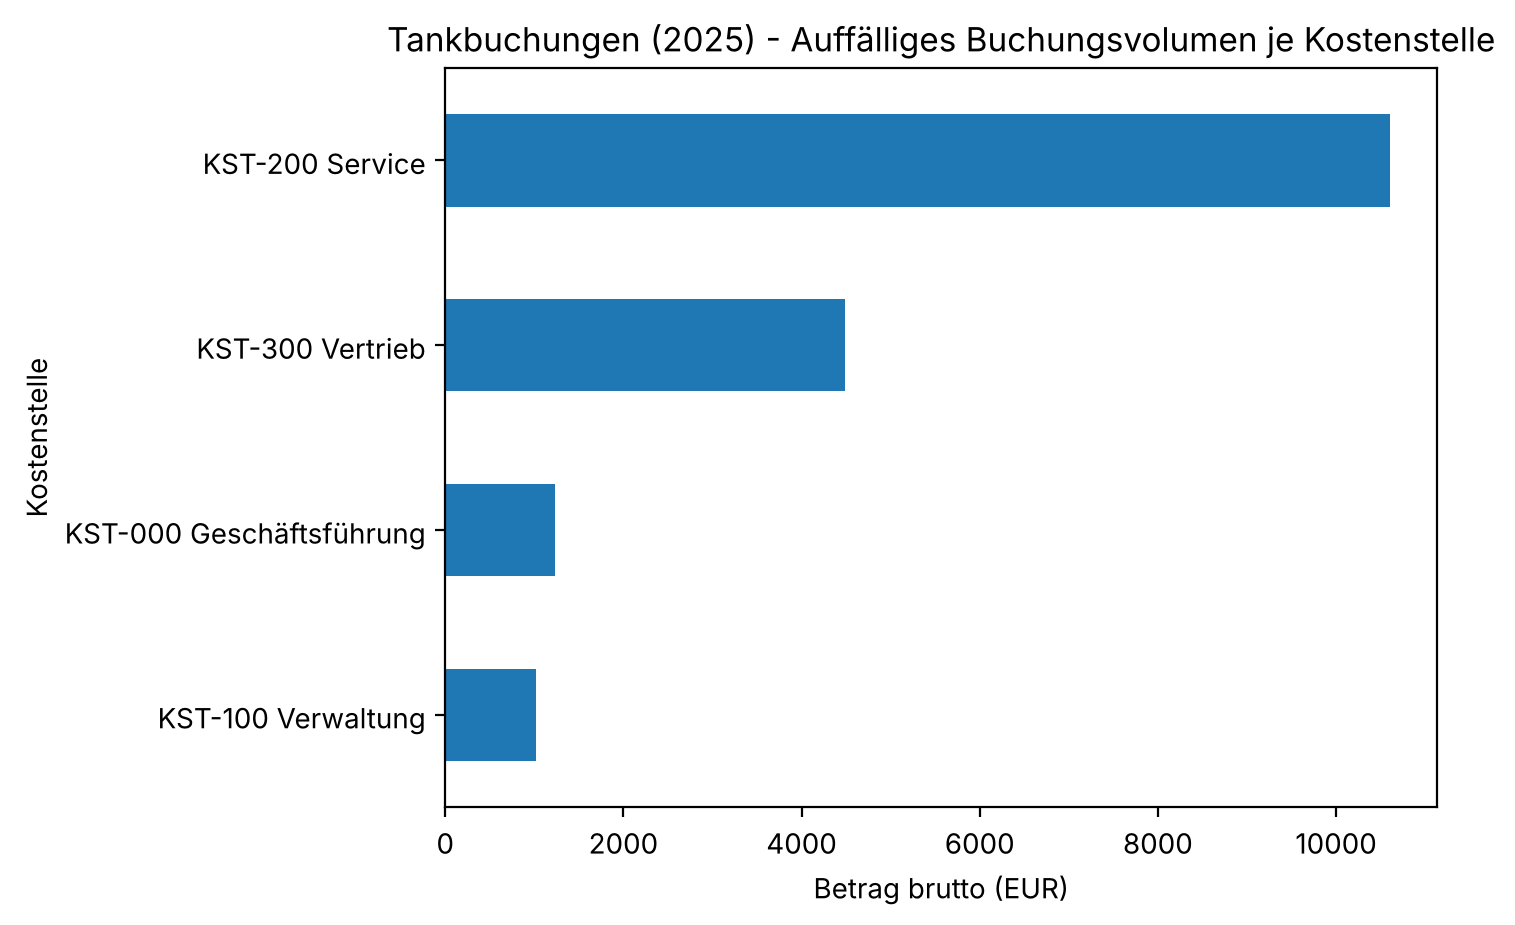

In [20]:
#Auffälliges Buchungsvolumen je Kostenstelle
daten[daten["kombi_flag"]].groupby("kostenstelle")["betrag_brutto"].sum().sort_values().plot(kind="barh")
plt.title("Tankbuchungen (2025) - Auffälliges Buchungsvolumen je Kostenstelle")
plt.xlabel("Betrag brutto (EUR)")
plt.ylabel("Kostenstelle")
plt.show()

In [21]:
#Ergebnisse speichern (CSV, Trennzeichen Semikolon und Dezimalkomma für Excel)
ergebnis_spalten = ["buchungs_id","zeitpunkt","fahrzeug_id","mitarbeiter_id","klasse","kostenstelle","tankstelle",
                    "kraftstoff_soll","kraftstoff_ist","tank_l","liter","preis_pro_liter","betrag_brutto","km_stand",
                    "km_diff","verbrauch_ist","auslastung","regel_flag","stat_flag","if_flag","if_score","kombi_flag",
                    "anzahl_methoden","begruendung","is_anomaly","anomalie_typ"]
daten.sort_values("zeitpunkt")[ergebnis_spalten].to_csv(f"ergebnisse_anomalie_erkennung_{JAHR}.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
kennzahlen_df.to_csv("kennzahlen_methoden.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
erkennung_df.to_csv("erkennungsrate_je_anomalietyp.csv", sep=";", decimal=",", encoding="utf-8-sig")
liste_df.to_csv("auffaelligkeitsliste.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
kpi_df.to_csv("kpi_uebersicht.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

## 8) Fazit
- **Datengrundlage:** 4.153 Tankbuchungen von 80 Fahrzeugen mit einem Volumen von rund 318.700 EUR; 126 Buchungen (3,0 %) wurden gezielt als Anomalien eingebaut. Literpreise (ADAC-Monatsmittel 2025), Verbräuche und Tankintervalle (Ø 6,9 Tage) liegen im realistischen Bereich.
- **Regeln:** höchste Präzision (Precision 0,82). Alle fachlich eindeutig definierbaren Fälle (Tankvolumen, Kraftstoff, km-Stand, Doppelbuchung, Arbeitszeit) werden zu 100 % erkannt. Preis- und Verbrauchsauffälligkeiten bleiben unentdeckt. Die 20 Fehlalarme sind ausschließlich legitime Sonntagstankungen im Notdienst.
- **Statistik (IQR / z-Score):** erkennt Preisausreißer (100 %) und überhöhten Verbrauch (94 %) und damit genau die Fälle, die Regeln nicht abdecken. Insgesamt Recall 0,43. Eine erste Version mit gemeinsamem Preisvergleich meldete viele Autobahntankstellen fälschlich, erst der getrennte Vergleich je Tankstellentyp löste das.
- **Isolation Forest:** findet ohne vorgegebene Regeln rund zwei Drittel der Anomalien (Precision und Recall ca. 0,66). Stark bei Doppelbuchungen und überhöhten Tankmengen, schwach bei Auffälligkeiten, die sich nur in einem Merkmal zeigen (km-Stand, Kraftstoffart).
- **Kombination:** alle 126 Anomalien werden gefunden (Recall 1,00) bei einer Trefferquote von 63 %. Das Controlling muss nur 4,8 % der Buchungen prüfen: rund 33 Stunden statt 208 Stunden bei Vollprüfung. Eine 10 %-Stichprobe hätte im Mittel nur etwa 13 Anomalien gefunden.
- **Vergleich (6.1):** One-Class-SVM (F1 allein 0,60–0,71) und Clustering (k-Means, DBSCAN: 0,68–0,81) hängen stark von ihren Parametern ab, die sich ohne Labels nicht einstellen lassen. In der Kombination mit Regeln und Statistik liegen alle Verfahren bei F1 0,69–0,79. Regeln und Statistik allein finden bereits 125 von 126 Anomalien; der Isolation Forest ergänzt einen Fall und 22 Fehlalarme. Sein Nutzen liegt bei unbekannten Mustern, die in den Demodaten nicht vorkommen.
- **Grenzen:** Die eingebauten Anomalien sind eindeutiger als reale Fälle, und die Ergebnisse hängen von den Annahmen (Preise, Verbrauch, Prüfzeiten) und vom Zufallsstartwert ab. Vor einem Einsatz wäre ein Test mit echten Tankkartendaten nötig.

Schlussfolgerung: Die Kombination aus nachvollziehbaren Regeln, Statistik und Isolation Forest schafft Transparenz über alle Tankbuchungen, senkt das Risiko unentdeckter Fehler und Manipulationen und reduziert den Prüfaufwand im Controlling deutlich.